In [1]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np

In [2]:
dataset_path = r"C:\Users\Loveleen\Downloads\COVID-19_Radiography_Dataset"

In [3]:
IMG_SIZE = (224,224)
BATCH_SIZE = 32

train_ds = tf.keras.preprocessing.image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

val_ds = tf.keras.preprocessing.image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

Found 16147 files belonging to 4 classes.
Using 12918 files for training.
Found 16147 files belonging to 4 classes.
Using 3229 files for validation.


In [4]:
class_names = train_ds.class_names
print(class_names)

['COVID', 'Lung_Opacity', 'Normal', 'Viral Pneumonia']


In [5]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.cache().shuffle(1000).prefetch(AUTOTUNE)
val_ds = val_ds.cache().prefetch(AUTOTUNE)

In [6]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomZoom(0.1)
])

In [7]:
model = tf.keras.Sequential([

    tf.keras.layers.Rescaling(1./255,
                              input_shape=(224,224,3)),

    data_augmentation,

    tf.keras.layers.Conv2D(32,(3,3),activation='relu'),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(64,(3,3),activation='relu'),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(128,(3,3),activation='relu'),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(256,(3,3),activation='relu'),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(256,activation='relu'),
    tf.keras.layers.Dropout(0.5),

    tf.keras.layers.Dense(128,activation='relu'),

    tf.keras.layers.Dense(4,activation='softmax')
])

C:\Users\Loveleen\anaconda3\Lib\site-packages\keras\src\layers\preprocessing\data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [8]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [9]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 24, 24, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 36864)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     9,437,440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,859,268 (37.61 MB)

 Trainable params: 9,859,268 (37.61 MB)

 Non-trainable params: 0 (0.00 B)

In [10]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20
)

Epoch 1/20


C:\Users\Loveleen\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


404/404 ━━━━━━━━━━━━━━━━━━━━ 327s 793ms/step - accuracy: 0.5325 - loss: 1.0336 - val_accuracy: 0.6689 - val_loss: 0.7484
Epoch 2/20
404/404 ━━━━━━━━━━━━━━━━━━━━ 693s 2s/step - accuracy: 0.6640 - loss: 0.7985 - val_accuracy: 0.7080 - val_loss: 0.7019
Epoch 3/20
404/404 ━━━━━━━━━━━━━━━━━━━━ 689s 2s/step - accuracy: 0.7100 - loss: 0.7176 - val_accuracy: 0.7687 - val_loss: 0.5989
Epoch 4/20
404/404 ━━━━━━━━━━━━━━━━━━━━ 641s 2s/step - accuracy: 0.7390 - loss: 0.6500 - val_accuracy: 0.7922 - val_loss: 0.5485
Epoch 5/20
404/404 ━━━━━━━━━━━━━━━━━━━━ 840s 2s/step - accuracy: 0.7517 - loss: 0.6197 - val_accuracy: 0.8058 - val_loss: 0.5127
Epoch 6/20
404/404 ━━━━━━━━━━━━━━━━━━━━ 994s 2s/step - accuracy: 0.7702 - loss: 0.5769 - val_accuracy: 0.8201 - val_loss: 0.4849
Epoch 7/20
404/404 ━━━━━━━━━━━━━━━━━━━━ 926s 2s/step - accuracy: 0.7816 - loss: 0.5567 - val_accuracy: 0.8229 - val_loss: 0.4851
Epoch 8/20
404/404 ━━━━━━━━━━━━━━━━━━━━ 721s 2s/step - accuracy: 0.7946 - loss: 0.5227 - val_accuracy: 0.

In [11]:
loss, accuracy = model.evaluate(val_ds)

print(f"Validation Loss: {loss:.4f}")
print(f"Validation Accuracy: {accuracy*100:.2f}%")

101/101 ━━━━━━━━━━━━━━━━━━━━ 44s 440ms/step - accuracy: 0.8712 - loss: 0.3324
Validation Loss: 0.3324
Validation Accuracy: 87.12%


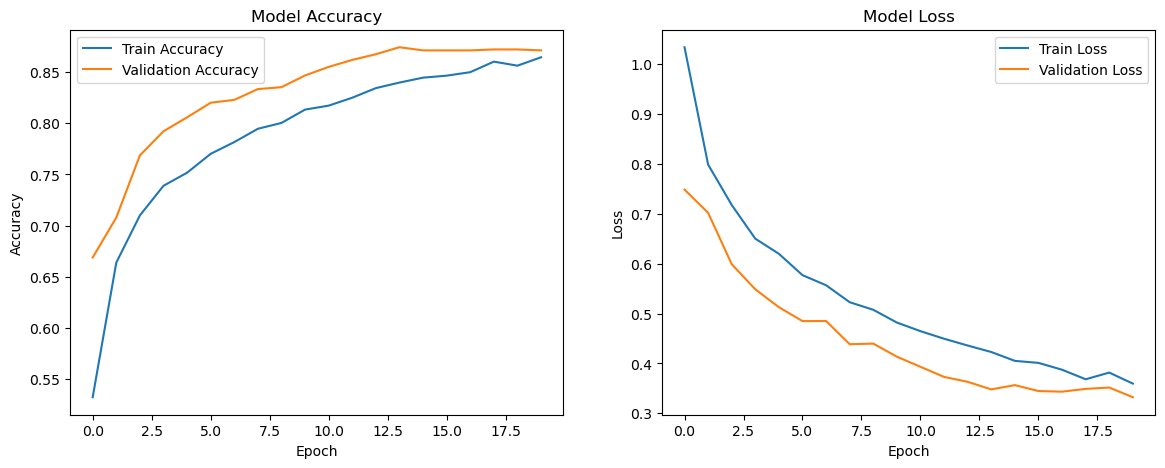

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14,5))

# Accuracy
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Model Accuracy")
plt.legend()

# Loss
plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Model Loss")
plt.legend()

plt.show()

In [ ]:
model.save("xray_disease_detector.keras")

In [ ]:
from tensorflow.keras.models import load_model

model = load_model("xray_disease_detector.keras")


In [ ]:
import numpy as np
from tensorflow.keras.preprocessing import image

img_path = r"C:\Users\Loveleen\Downloads\COVID-19_Radiography_Dataset\COVID\COVID-1.png"

img = image.load_img(img_path, target_size=(224,224))
img = image.img_to_array(img)
img = img / 255.0
img = np.expand_dims(img, axis=0)

prediction = model.predict(img)

predicted_class = class_names[np.argmax(prediction)]
confidence = np.max(prediction)

print("Prediction:", predicted_class)
print(f"Confidence: {confidence*100:.2f}%")

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np

y_true = []
y_pred = []

for images, labels in val_ds:
    preds = model.predict(images, verbose=0)
    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(preds, axis=1))

cm = confusion_matrix(y_true, y_pred)

print(cm)

print(classification_report(
    y_true,
    y_pred,
    target_names=train_ds.class_names
))

In [ ]:
plt.figure(figsize=(12,12))

for images, labels in val_ds.take(1):
    predictions = model.predict(images, verbose=0)

    for i in range(9):
        plt.subplot(3,3,i+1)
        plt.imshow(images[i].numpy().astype("uint8"))
        pred = class_names[np.argmax(predictions[i])]
        actual = class_names[labels[i]]
        plt.title(f"P: {pred}\nA: {actual}")
        plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
prediction = model.predict(img)

predicted_class = class_names[np.argmax(prediction)]
confidence = np.max(prediction)

print("Prediction:", predicted_class)
print(f"Confidence: {confidence*100:.2f}%")

In [ ]:
y_true = []
y_pred = []

for images, labels in val_ds:
    predictions = model.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

In [ ]:
cm = confusion_matrix(y_true, y_pred)

print(cm)

In [ ]:
plt.figure(figsize=(8,6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")
plt.show()

In [ ]:
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))

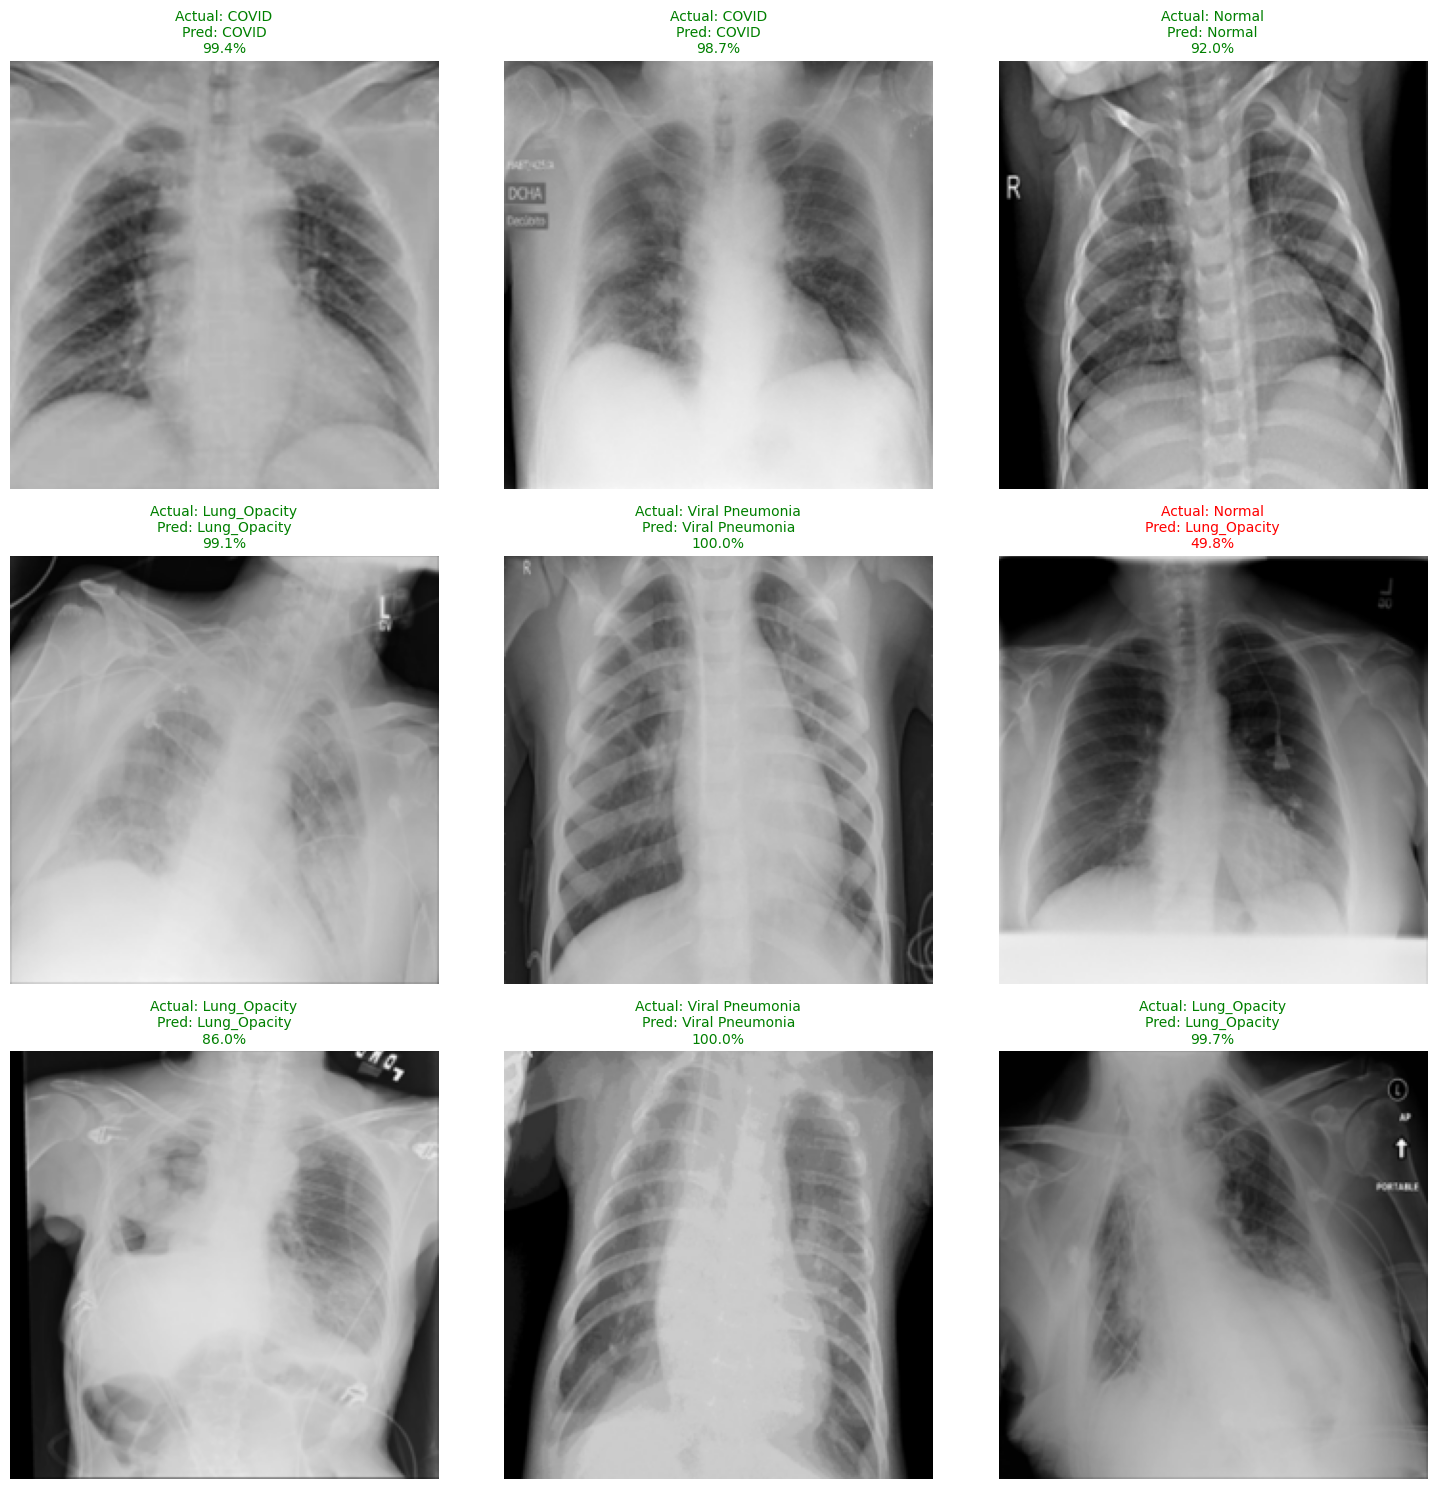

In [21]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(15,15))

for images, labels in val_ds.take(1):

    predictions = model.predict(images, verbose=0)

    for i in range(9):
        plt.subplot(3,3,i+1)

        plt.imshow(images[i].numpy().astype("uint8"))

        actual = class_names[labels[i]]
        predicted = class_names[np.argmax(predictions[i])]
        confidence = np.max(predictions[i]) * 100

        if actual == predicted:
            color = "green"
        else:
            color = "red"

        plt.title(
            f"Actual: {actual}\nPred: {predicted}\n{confidence:.1f}%",
            color=color,
            fontsize=10
        )

        plt.axis("off")

plt.tight_layout()
plt.show()

In [22]:
model.save("xray_disease_detector.keras")

In [23]:
from tensorflow.keras.models import load_model

model = load_model("xray_disease_detector.keras")

In [24]:
import json

with open("class_names.json", "w") as f:
    json.dump(class_names, f)

In [25]:
import json

with open("class_names.json", "r") as f:
    class_names = json.load(f)

FileNotFoundError: [Errno 2] No such file or directory: 'YOUR_IMAGE_PATH.png'